# 01 · Dataset Exploration

**Artemis-X - AI perception for lunar rock and obstacle detection**

**Objective.** Characterise the data sources available for lunar rock detection and identify the problems a detector must cope with before any modelling decision is made (Task A).

**Research questions**

1. What data are available, at what resolution and in what quantity?
2. How complete and how reliable are the original annotations?
3. Which data-quality problems constrain the later pipeline?

**Inputs (published, pixel-free artifacts)**

- `artifacts/data/artificial_lunar_analysis.json`
- `artifacts/data/data_quality_report.json`
- `artifacts/data/dataset_inventory.json`
- `artifacts/figures/a_*.png`

> **Provisional results.** All labels were produced by an automated pipeline (S2-H policy) and have **not** been verified by humans. Metrics are measured on synthetic renders only and do not establish performance on real lunar imagery or readiness for rover deployment.

## Setup
The notebook imports the `artemis_x` package from `src/` and reads only published artifacts. It never trains a model, rebuilds a dataset or evaluates the held-out test split.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "artemis_x").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from artemis_x.config import paths
from artemis_x.reporting import artifacts as A, plots as P
P.use_style()
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 90)
# Dataset pixels are never committed (redistribution licence unconfirmed). Set ARTEMIS_SHOW_LOCAL_IMAGES=1 to view
# local images when the dataset folder is present.
SHOW_LOCAL_IMAGES = os.environ.get("ARTEMIS_SHOW_LOCAL_IMAGES") == "1" and paths.local_dataset_available()
FIG = paths.ARTIFACTS / "figures"
print("artemis_x ready | local dataset present:", paths.local_dataset_available(), "| showing local images:", SHOW_LOCAL_IMAGES)

artemis_x ready | local dataset present: True | showing local images: False


## 1. Background and data sources
Three sources were inventoried (Task A):

| Source | Content | Role in Artemis-X |
|---|---|---|
| **Artificial Lunar Landscape** (Kaggle release) | 9,766 synthetic lunar scenes, each with a photorealistic *render*, a semantic *ground* mask (sky / small rocks / large rocks) and a *clean* mask; a CSV of large-rock boxes | **Primary training and evaluation data** |
| **NASA POLAR** (3 terrains) | Real stereo images of a lunar-analogue testbed: 12-bit in 16-bit PNG, exposure brackets, LiDAR | Real-domain reference; *not* used for training or evaluation yet |
| **POLAR-Sim** labels (github.com/uwsbel/POLAR-Sim, CC0) | YOLO boxes and segmentation polygons for POLAR | Annotation reference for the real domain |

The Artificial Lunar renders are 720 x 480 px, 8-bit RGB, rendered with sky, terrain and rocks of all sizes.

In [2]:
A.dataset_overview()

,Quantity,Value
0,Artificial Lunar scenes (render / ground / clean),"9,766 x 3"
1,Image size,"720 x 480 px, 8-bit RGB"
2,Original CSV rock boxes (large rocks only),"18,867"
3,Near-duplicate render pairs (dHash <= 3),376
4,"Real lunar photos (PCAM/TCAM, qualitative only)",36
5,Frames eligible after anomaly exclusion,"9,193"


## 2. Original annotations are incomplete
The Kaggle CSV boxes only cover **large rocks**. The *ground* masks also contain thousands of smaller rocks that a rover camera sees
and that a detector would otherwise learn as background. The table summarises the CSV box geometry.

In [3]:
a = A.load_json("data/artificial_lunar_analysis.json")
bb = a["bounding_boxes"]
pd.DataFrame({k: bb[k] for k in ("area_px", "area_frac_of_image", "aspect_w_over_h")}).T[["count", "min", "p05", "median", "mean", "p95", "max"]]

,count,min,p05,median,mean,p95,max
area_px,18867.0,441.000,594.000,1833.000,5654.676,22029.400,325920.000
area_frac_of_image,18867.0,0.001,0.002,0.005,0.016,0.064,0.943
aspect_w_over_h,18867.0,0.126,0.760,1.371,1.580,3.147,8.000


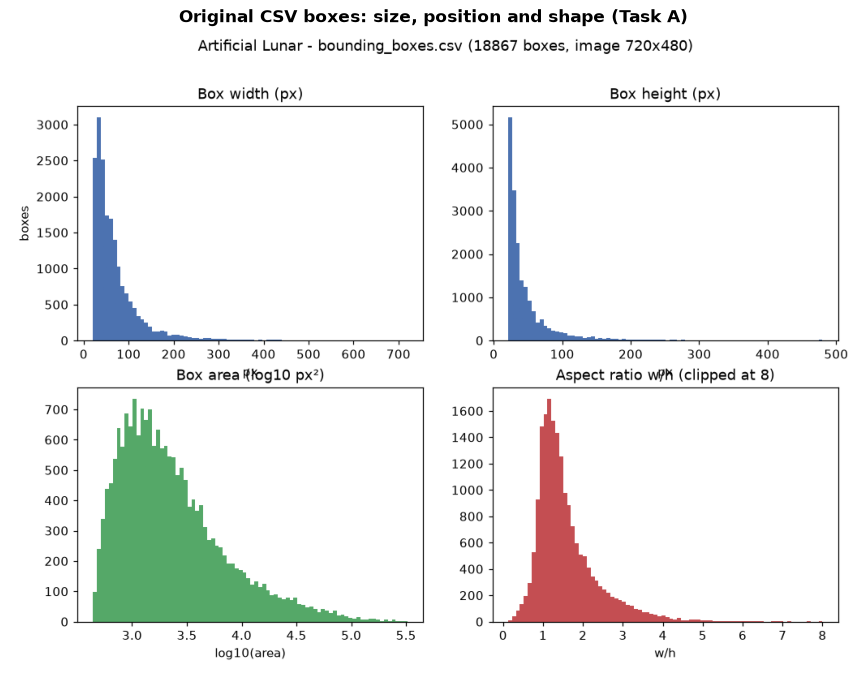

In [4]:
P.show_png(FIG / "a_bbox_distributions.png", "Original CSV boxes: size, position and shape (Task A)")

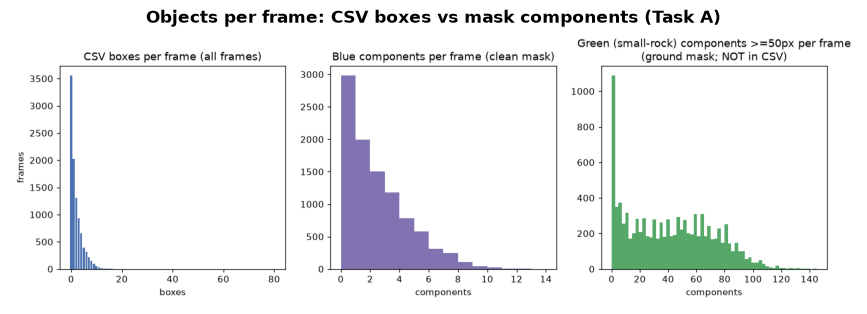

In [5]:
P.show_png(FIG / "a_objects_per_frame.png", "Objects per frame: CSV boxes vs mask components (Task A)")

## 3. Rendering conditions and author-flagged anomalies
The dataset authors list frames with known problems (camera anomalies, ground-facing views, render/mask mismatches, heavy shadow).
These **573 frames were excluded**, leaving **9,193 eligible frames**.

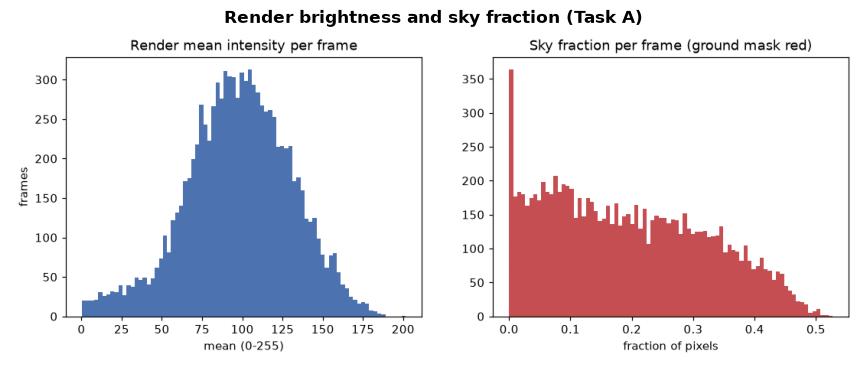

In [6]:
P.show_png(FIG / "a_render_intensity_and_sky.png", "Render brightness and sky fraction (Task A)")

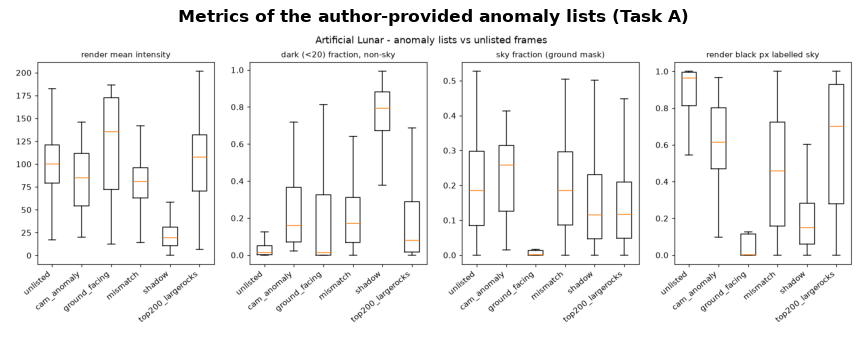

In [7]:
P.show_png(FIG / "a_anomaly_list_metrics.png", "Metrics of the author-provided anomaly lists (Task A)")

## 4. Data-quality register
Every issue found in Task A, with its severity. HIGH issues shaped the later design decisions.

In [8]:
q = A.quality_issues()
display(q["severity"].value_counts().rename("issues").to_frame().T)
q

severity,MEDIUM,LOW,HIGH
issues,8,8,4


,id,severity,source,issue
0,AL-01,HIGH,artificial-lunar,bounding_boxes.csv annotates only large (blue-mask) rocks
1,NP-01,HIGH,nasa-polar,Images are 12-bit single-channel data in 16-bit PNG containers
2,NP-02,HIGH,nasa-polar,Heavy redundancy: 7-8 exposure brackets x stereo x lighting of only 3 camera positions...
3,PS-05,HIGH,polar-sim,Rock boxes re-used across exposures of a bracket (93% of brackets have identical rock ...
4,AL-02,MEDIUM,artificial-lunar,CSV boxes without a matching blue-mask component (IoU<0.5)
5,AL-04,MEDIUM,artificial-lunar,Author-provided anomaly lists flag frames with known render/label problems
6,HK-03,MEDIUM,analysis,Errors logged during analysis
7,MT-01,MEDIUM,nasa-polar+polar-sim,NASA images without a detection label file
8,NP-04,MEDIUM,nasa-polar,LiDAR ground truth only per position (3 point clouds per terrain); CAM_LIDAR_* must be...
9,PS-01,MEDIUM,polar-sim,Stray non-canonical label files (copies / 'good' variants / metadata / .DS_Store)


## 5. Local-only visual examples
Sample renders are displayed only when the local dataset is present **and** `ARTEMIS_SHOW_LOCAL_IMAGES=1`, because the
redistribution licence of the images has not been confirmed. Committed outputs therefore contain no dataset pixels.

In [9]:
if SHOW_LOCAL_IMAGES:
    from PIL import Image
    import matplotlib.pyplot as plt
    ids = [189, 5589, 586]
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    for a_, i in zip(ax, ids):
        a_.imshow(Image.open(paths.RAW_RENDERS / f"render{i:04d}.png")); a_.set_title(f"render{i:04d}"); a_.axis("off")
    plt.show()
else:
    print("Dataset images not shown (licence unconfirmed or dataset absent). See docs/DATASET.md to obtain the data.")

Dataset images not shown (licence unconfirmed or dataset absent). See docs/DATASET.md to obtain the data.


## Provenance
Each artifact below is a verified copy (or path-sanitised derivative) of a historical experiment output; `scripts/verify_artifacts.py` re-checks every hash.

In [10]:
A.provenance(['data/artificial_lunar_analysis.json', 'data/data_quality_report.json', 'figures/a_bbox_distributions.png'])

,artifact,mode,source (local experiments/),sha256
0,artifacts/data/artificial_lunar_analysis.json,COPY,experiments/dataset-exploration/artificial_lunar_analysis.json,4bae581ece2b4eb2...
1,artifacts/data/data_quality_report.json,COPY,experiments/dataset-exploration/data_quality_report.json,ba7153d33eab5ae6...
2,artifacts/figures/a_bbox_distributions.png,COPY,experiments/dataset-exploration/figures/al_bbox_distributions.png,d77456540d60d79b...


## Conclusion
- The synthetic Artificial Lunar renders are the only source large and consistently labelled enough for training.
- The **original CSV labels cover only large rocks** (HIGH issue AL-01), so the rock masks must be used to label smaller rocks. This
  is the subject of the annotation analysis.
- NASA POLAR is a valuable *real-domain* check but needs a validated 12-bit to 8-bit conversion first. It is excluded from all
  reported metrics.
- 376 near-duplicate render pairs mean that splits must be **grouped**, which is handled in notebook 04.

**Next:** [02_annotation_analysis.ipynb](02_annotation_analysis.ipynb)